# Student Performance Analysis

A beginner-friendly Data Analyst portfolio project using **Python, Pandas, NumPy, Matplotlib, Seaborn and Excel**.

**Goal:** clean a student marks dataset, analyse performance (students, subjects, gender, class, pass / fail), create charts and export an Excel report.

**Dataset:** `data/student_performance.csv` - 5 subjects (Mathematics, Science, English, Social Studies, Computer), marks out of 100. The raw file contains deliberate data-quality problems (missing marks, duplicates, impossible marks, invalid records) so the cleaning steps have real work to do.

**Pass rule:** a student passes only if they score **at least 40 in every subject**.

**How to run:** open this notebook from the `notebooks/` folder and choose *Run -> Run All Cells*. All paths are relative to the project folder, and the notebook uses exactly the same code as `src/analysis.py`.


## STEP 0: Import libraries and set up folders

In [ ]:
import sys
from pathlib import Path

import warnings

import numpy as np
import pandas as pd
import matplotlib

# When running as a normal script, save charts without opening windows
IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import seaborn as sns
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

# ---- Folder paths (relative to the project folder, so they work on any PC) ----
try:
    BASE_DIR = Path(__file__).resolve().parent.parent        # script is in src/
except NameError:
    # Running inside a notebook (notebooks/ folder)
    BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_FILE = BASE_DIR / "data" / "student_performance.csv"
CLEAN_FILE = BASE_DIR / "data" / "cleaned_student_performance.csv"
CHARTS_DIR = BASE_DIR / "outputs" / "charts"
EXCEL_FILE = BASE_DIR / "outputs" / "student_performance_report.xlsx"

CHARTS_DIR.mkdir(parents=True, exist_ok=True)

# ---- Project settings ----
SUBJECTS = ["Mathematics", "Science", "English", "Social_Studies", "Computer"]
BASE_COLUMNS = ["Student_ID", "Student_Name", "Gender", "Age", "Class"] + SUBJECTS
PASS_MARK = 40            # a student passes if they score at least 40 in EVERY subject

# Hide a harmless version notice that seaborn can trigger with the newest matplotlib
warnings.filterwarnings("ignore", message=".*vert.*", category=matplotlib.MatplotlibDeprecationWarning)

# ---- Chart colours and style ----
sns.set_theme(style="whitegrid", font_scale=1.0)
SUBJECT_COLORS = ["#1F4E79", "#2E86AB", "#F6AE2D", "#F26419", "#55A630"]
GENDER_COLORS = {"Male": "#2E86AB", "Female": "#E07A5F"}
RESULT_COLORS = {"Pass": "#2E8B57", "Fail": "#C0392B"}


def short_path(path):
    """Show a path relative to the project folder (shorter and not PC-specific)."""
    return str(Path(path).relative_to(BASE_DIR))


def save_chart(file_name):
    """Save the current chart as a PNG file (and show it when in a notebook)."""
    plt.tight_layout()
    plt.savefig(CHARTS_DIR / file_name, dpi=150, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close()
    print("Chart saved:", file_name)


def make_pass_fail_table(data, group_column):
    """Count Pass / Fail students for each group (for example each Gender)."""
    table = pd.crosstab(data[group_column], data["Result"])
    table = table.reindex(columns=["Pass", "Fail"], fill_value=0)
    table["Total_Students"] = table["Pass"] + table["Fail"]
    table["Pass_Percentage"] = (table["Pass"] / table["Total_Students"] * 100).round(2)
    table = table.rename(columns={"Pass": "Passed", "Fail": "Failed"})
    table = table[["Total_Students", "Passed", "Failed", "Pass_Percentage"]]
    return table.reset_index()


print("Setup complete. Project folder:", BASE_DIR.name)

Setup complete. Project folder: Student_Performance_Analysis


## STEP 1: Load the raw dataset

In [ ]:
# Read the CSV file. If the file is missing, show a clear message.
try:
    df = pd.read_csv(RAW_FILE)
except FileNotFoundError:
    raise FileNotFoundError(
        "Could not find " + short_path(RAW_FILE) + "\n"
        "Create it first by running:  python src/generate_dataset.py"
    )

print("Rows and columns:", df.shape)
print()
print(df.head().to_string(index=False))
print()
print("Data types:")
print(df.dtypes.to_string())

Rows and columns: (123, 10)

Student_ID   Student_Name Gender  Age  Class  Mathematics  Science  English Social_Studies  Computer
      S001 Anil Chowdhury   Male 15.0     10         34.0     50.0     49.0             50      45.0
      S002    Divya Mehta Female 15.0      9         84.0     75.0     89.0             76      94.0
      S003   Daniel Kumar   Male 18.0     12         61.0     65.0     76.0             74      76.0
      S004     Vivek Bose   Male 18.0     12         54.0     70.0     78.0             65      61.0
      S005   Rahul Pillai   Male 17.0     11         59.0     51.0     62.0             60      63.0

Data types:
Student_ID            str
Student_Name          str
Gender                str
Age               float64
Class               int64
Mathematics       float64
Science           float64
English           float64
Social_Studies        str
Computer          float64


## STEP 2: Check and fix data types

In [ ]:
# Marks and Age must be numbers. Text such as "AB" (absent) is turned into a
# missing value (NaN) so it can be handled in the next steps.
for column in SUBJECTS + ["Age"]:
    as_number = pd.to_numeric(df[column], errors="coerce")
    not_a_number = df[column].notna() & as_number.isna()
    if not_a_number.any():
        bad_values = df.loc[not_a_number, column].tolist()
        print("Column", column, "has text instead of numbers:", bad_values)
    df[column] = as_number

print()
print("Data types after conversion:")
print(df.dtypes.to_string())

Column Social_Studies has text instead of numbers: ['AB']

Data types after conversion:
Student_ID            str
Student_Name          str
Gender                str
Age               float64
Class               int64
Mathematics       float64
Science           float64
English           float64
Social_Studies    float64
Computer          float64


## STEP 3: Check missing values

In [ ]:
# Count how many cells are empty in each column.
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0].to_string())
print("Total missing cells:", int(missing_counts.sum()))

Missing values per column:
Student_Name      1
Age               1
Mathematics       2
Science           1
English           2
Social_Studies    1
Computer          1
Total missing cells: 9


## STEP 4: Check and remove duplicate records

In [ ]:
# The same student record entered twice would count that student two times.
duplicate_count = int(df.duplicated().sum())
print("Exact duplicate rows found:", duplicate_count)
df = df.drop_duplicates()

# A Student_ID must also be unique, so keep only the first one of each ID
duplicate_ids = int(df.duplicated(subset="Student_ID").sum())
print("Repeated Student_IDs found:", duplicate_ids)
df = df.drop_duplicates(subset="Student_ID", keep="first")
print("Rows after removing duplicates:", len(df))

Exact duplicate rows found: 3
Repeated Student_IDs found: 0
Rows after removing duplicates: 120


## STEP 5: Check and remove invalid student records

In [ ]:
# Clean up text columns first (remove extra spaces, fix capital letters)
df["Student_Name"] = df["Student_Name"].str.strip().replace("", np.nan)
df["Gender"] = df["Gender"].str.strip().str.title()

# A record is invalid if:
#   - the student has no ID or no name
#   - the gender is not Male / Female
#   - the age is not realistic for school (10 to 20 years)
#   - the class is not 9, 10, 11 or 12
invalid_records = (
    df["Student_ID"].isnull()
    | df["Student_Name"].isnull()
    | ~df["Gender"].isin(["Male", "Female"])
    | (df["Age"] < 10)
    | (df["Age"] > 20)
    | ~df["Class"].isin([9, 10, 11, 12])
)

print("Invalid student records found:", int(invalid_records.sum()))
if invalid_records.any():
    print(df[invalid_records].to_string(index=False))

# Remove the invalid records
df = df[~invalid_records].copy()
print("Rows after removing invalid records:", len(df))

Invalid student records found: 2
Student_ID Student_Name Gender  Age  Class  Mathematics  Science  English  Social_Studies  Computer
      S010          NaN Female 16.0     11         71.0     74.0     79.0            71.0      70.0
      S067   Amit Menon   Male 45.0      9         73.0     63.0    100.0           100.0      85.0
Rows after removing invalid records: 118


## STEP 6: Validate marks (must be between 0 and 100)

In [ ]:
# Marks below 0 or above 100 are typing mistakes. We cannot know the real
# value, so we mark them as missing (NaN) and fill them in the next step.
for subject in SUBJECTS:
    wrong_marks = (df[subject] < 0) | (df[subject] > 100)
    if wrong_marks.any():
        print(subject, "-> marks outside 0-100:", df.loc[wrong_marks, subject].tolist())
        df.loc[wrong_marks, subject] = np.nan

print("Marks outside the 0-100 range have been set to missing.")

Mathematics -> marks outside 0-100: [105.0]
English -> marks outside 0-100: [-5.0]
Computer -> marks outside 0-100: [150.0]
Marks outside the 0-100 range have been set to missing.


## STEP 7: Handle missing values

In [ ]:
# - Missing marks are filled with the MEDIAN mark of that subject
#   (the median is not affected by very high or very low marks).
# - A missing Age is filled with the median age of the same class.
for subject in SUBJECTS:
    median_mark = round(df[subject].median())
    missing_here = int(df[subject].isnull().sum())
    df[subject] = df[subject].fillna(median_mark)
    if missing_here > 0:
        print(subject, ": filled", missing_here, "missing value(s) with", median_mark)

df["Age"] = df["Age"].fillna(df.groupby("Class")["Age"].transform("median"))

# Marks and Age are whole numbers, so store them as integers
df[SUBJECTS] = df[SUBJECTS].round().astype(int)
df["Age"] = df["Age"].round().astype(int)

Mathematics : filled 3 missing value(s) with 64
Science : filled 1 missing value(s) with 66
English : filled 3 missing value(s) with 72
Social_Studies : filled 1 missing value(s) with 70
Computer : filled 2 missing value(s) with 70


## STEP 8: Final checks and save the cleaned dataset

In [ ]:
df = df[BASE_COLUMNS].reset_index(drop=True)

print("Missing values left:", int(df.isnull().sum().sum()))
print("Duplicate rows left:", int(df.duplicated().sum()))
print("Lowest mark:", int(df[SUBJECTS].min().min()), "| Highest mark:", int(df[SUBJECTS].max().max()))
print("Cleaned dataset shape:", df.shape)

try:
    df.to_csv(CLEAN_FILE, index=False)
    print("Cleaned data saved to:", short_path(CLEAN_FILE))
except PermissionError:
    print("Could not save", CLEAN_FILE.name, "- close it if it is open in another program.")

clean_df = df.copy()      # keep a copy of the cleaned data for the Excel report

Missing values left: 0
Duplicate rows left: 0
Lowest mark: 6 | Highest mark: 100
Cleaned dataset shape: (118, 10)
Cleaned data saved to: data/cleaned_student_performance.csv


## STEP 9: Create new columns for student performance

In [ ]:
# Total, average, highest / lowest mark and Pass / Fail result for every student.
df["Total_Marks"] = df[SUBJECTS].sum(axis=1)
df["Average_Marks"] = df[SUBJECTS].mean(axis=1).round(2)

df["Highest_Mark"] = df[SUBJECTS].max(axis=1)
df["Highest_Subject"] = df[SUBJECTS].idxmax(axis=1)
df["Lowest_Mark"] = df[SUBJECTS].min(axis=1)
df["Lowest_Subject"] = df[SUBJECTS].idxmin(axis=1)

# Result: Pass only if the student scored at least PASS_MARK in every subject
df["Result"] = np.where(df[SUBJECTS].min(axis=1) >= PASS_MARK, "Pass", "Fail")


# List the subjects in which a student scored below the pass mark
def find_failed_subjects(row):
    failed = [subject for subject in SUBJECTS if row[subject] < PASS_MARK]
    return ", ".join(failed) if failed else "None"


df["Failed_Subjects"] = df.apply(find_failed_subjects, axis=1)

# Grade is based on the average marks (students who failed get grade F)
grade_bins = [0, 40, 50, 60, 70, 80, 90, 101]
grade_names = ["F", "E", "D", "C", "B", "A", "A+"]
df["Grade"] = pd.cut(df["Average_Marks"], bins=grade_bins, labels=grade_names, right=False).astype(str)
df.loc[df["Result"] == "Fail", "Grade"] = "F"

# Rank 1 = highest total marks
df["Rank"] = df["Total_Marks"].rank(method="min", ascending=False).astype(int)

print(df[["Student_ID", "Student_Name", "Total_Marks", "Average_Marks", "Result", "Grade", "Rank"]].head(8).to_string(index=False))

Student_ID   Student_Name  Total_Marks  Average_Marks Result Grade  Rank
      S001 Anil Chowdhury          228           45.6   Fail     F   110
      S002    Divya Mehta          418           83.6   Pass     A    11
      S003   Daniel Kumar          352           70.4   Pass     B    57
      S004     Vivek Bose          328           65.6   Pass     C    76
      S005   Rahul Pillai          295           59.0   Pass     D    94
      S006 Siddharth Bose          348           69.6   Pass     C    60
      S007   Shruti Reddy          405           81.0   Pass     A    16
      S008       Anil Rao          376           75.2   Pass     B    29


## STEP 10: EDA - overall statistics

In [ ]:
total_students = len(df)
all_marks = df[SUBJECTS].to_numpy()

print("Total number of students :", total_students)
print("Average marks (all subjects):", round(all_marks.mean(), 2))
print("Maximum marks            :", int(all_marks.max()))
print("Minimum marks            :", int(all_marks.min()))

# Who got the highest and the lowest single mark?
marks_long = df.melt(id_vars=["Student_ID", "Student_Name"], value_vars=SUBJECTS,
                     var_name="Subject", value_name="Marks")
best_row = marks_long.loc[marks_long["Marks"].idxmax()]
worst_row = marks_long.loc[marks_long["Marks"].idxmin()]
print()
print("Highest single mark:", best_row["Marks"], "-", best_row["Student_Name"], "in", best_row["Subject"])
print("Lowest single mark :", worst_row["Marks"], "-", worst_row["Student_Name"], "in", worst_row["Subject"])

# Average of every student (first 5 students shown)
print()
print("Average marks of each student (first 5):")
print(df[["Student_Name", "Average_Marks", "Highest_Mark", "Lowest_Mark"]].head().to_string(index=False))

Total number of students : 118
Average marks (all subjects): 67.16
Maximum marks            : 100
Minimum marks            : 6

Highest single mark: 100 - Aisha Sharma in Mathematics
Lowest single mark : 6 - Mary Menon in English

Average marks of each student (first 5):
  Student_Name  Average_Marks  Highest_Mark  Lowest_Mark
Anil Chowdhury           45.6            50           34
   Divya Mehta           83.6            94           75
  Daniel Kumar           70.4            76           61
    Vivek Bose           65.6            78           54
  Rahul Pillai           59.0            63           51


## STEP 11: EDA - subject-wise analysis

In [ ]:
# One row per subject with average, highest, lowest and pass / fail counts.
subject_df = pd.DataFrame({
    "Subject": SUBJECTS,
    "Average_Marks": df[SUBJECTS].mean().round(2).values,
    "Highest_Marks": df[SUBJECTS].max().values,
    "Lowest_Marks": df[SUBJECTS].min().values,
    "Median_Marks": df[SUBJECTS].median().values,
    "Std_Deviation": df[SUBJECTS].std().round(2).values,
    "Passed_Students": (df[SUBJECTS] >= PASS_MARK).sum().values,
    "Failed_Students": (df[SUBJECTS] < PASS_MARK).sum().values,
})
subject_df["Pass_Percentage"] = (subject_df["Passed_Students"] / total_students * 100).round(2)
subject_df["Rank_By_Average"] = subject_df["Average_Marks"].rank(ascending=False, method="min").astype(int)

# Highest and lowest performing subject (based on average marks)
best_subject = subject_df.loc[subject_df["Average_Marks"].idxmax(), "Subject"]
worst_subject = subject_df.loc[subject_df["Average_Marks"].idxmin(), "Subject"]
subject_df["Remark"] = ""
subject_df.loc[subject_df["Subject"] == best_subject, "Remark"] = "Highest-performing subject"
subject_df.loc[subject_df["Subject"] == worst_subject, "Remark"] = "Lowest-performing subject"

print(subject_df.to_string(index=False))
print()
print("Highest-performing subject:", best_subject)
print("Lowest-performing subject :", worst_subject)

       Subject  Average_Marks  Highest_Marks  Lowest_Marks  Median_Marks  Std_Deviation  Passed_Students  Failed_Students  Pass_Percentage  Rank_By_Average                     Remark
   Mathematics          62.25            100            14          64.0          16.21              106               12            89.83                5  Lowest-performing subject
       Science          65.68            100            17          66.0          16.06              110                8            93.22                4                           
       English          69.47            100             6          72.0          16.20              112                6            94.92                2                           
Social_Studies          68.77            100            17          70.0          16.58              112                6            94.92                3                           
      Computer          69.60            100            20          70.0          14.

## STEP 12: EDA - gender-wise and class-wise performance

In [ ]:
gender_df = df.groupby("Gender").agg(
    Students=("Student_ID", "count"),
    Average_Marks=("Average_Marks", "mean"),
).round(2).reset_index()
gender_subject_avg = df.groupby("Gender")[SUBJECTS].mean().round(2)

class_df = df.groupby("Class").agg(
    Students=("Student_ID", "count"),
    Average_Marks=("Average_Marks", "mean"),
).round(2).reset_index()

print("Gender-wise performance:")
print(gender_df.to_string(index=False))
print()
print("Gender-wise subject averages:")
print(gender_subject_avg.to_string())
print()
print("Class-wise performance:")
print(class_df.to_string(index=False))

Gender-wise performance:
Gender  Students  Average_Marks
Female        63          68.36
  Male        55          65.78

Gender-wise subject averages:
        Mathematics  Science  English  Social_Studies  Computer
Gender                                                         
Female        64.17    66.11    70.54           69.65     71.30
Male          60.05    65.18    68.25           67.76     67.65

Class-wise performance:
 Class  Students  Average_Marks
     9        32          69.61
    10        26          67.07
    11        32          67.36
    12        28          64.19


## STEP 13: EDA - pass / fail analysis

In [ ]:
pass_count = int((df["Result"] == "Pass").sum())
fail_count = int((df["Result"] == "Fail").sum())
pass_percentage = round(pass_count / total_students * 100, 2)

print("Passed students:", pass_count)
print("Failed students:", fail_count)
print("Overall pass percentage:", pass_percentage, "%")

pass_fail_gender = make_pass_fail_table(df, "Gender")
pass_fail_class = make_pass_fail_table(df, "Class")
print()
print(pass_fail_gender.to_string(index=False))
print()
print(pass_fail_class.to_string(index=False))

# Students who failed (lowest average first)
failed_students = df[df["Result"] == "Fail"].sort_values("Average_Marks")
failed_students = failed_students[["Student_ID", "Student_Name", "Gender", "Class",
                                   "Average_Marks", "Failed_Subjects"]]
print()
print("Students who failed:")
print(failed_students.to_string(index=False))

Passed students: 102
Failed students: 16
Overall pass percentage: 86.44 %

Gender  Total_Students  Passed  Failed  Pass_Percentage
Female              63      56       7            88.89
  Male              55      46       9            83.64

 Class  Total_Students  Passed  Failed  Pass_Percentage
     9              32      29       3            90.62
    10              26      22       4            84.62
    11              32      28       4            87.50
    12              28      23       5            82.14

Students who failed:
Student_ID   Student_Name Gender  Class  Average_Marks                                         Failed_Subjects
      S074     Mary Menon Female     12           14.8 Mathematics, Science, English, Social_Studies, Computer
      S065  Pallavi Gupta Female     12           27.6 Mathematics, Science, English, Social_Studies, Computer
      S019   Neha Chauhan Female     12           34.4          Mathematics, Science, Social_Studies, Computer
      S045

## STEP 14: EDA - top 10 students

In [ ]:
# Sort by total marks (highest first). Names are used to break ties.
top_students = df.sort_values(["Total_Marks", "Student_Name"], ascending=[False, True]).head(10)
top_students = top_students[["Rank", "Student_ID", "Student_Name", "Gender", "Class"]
                            + SUBJECTS + ["Total_Marks", "Average_Marks", "Grade"]]
print(top_students.to_string(index=False))

 Rank Student_ID     Student_Name Gender  Class  Mathematics  Science  English  Social_Studies  Computer  Total_Marks  Average_Marks Grade
    1       S082     Aisha Sharma Female     11          100      100       94             100        93          487           97.4    A+
    2       S040      Harsh Yadav   Male     11           89       92       93             100        87          461           92.2    A+
    3       S056      Dev Chauhan   Male     12           80       97       84             100        90          451           90.2    A+
    4       S112    Rahul Agarwal   Male      9           85       90       90              92        89          446           89.2     A
    5       S072 Daniel Chowdhury   Male      9           79      100       86              85        82          432           86.4     A
    5       S035      Rashmi Goud Female      9           94       76       92              81        89          432           86.4     A
    7       S081    Pallavi

## STEP 15: Chart 1 - Subject-wise average marks (bar chart)

Chart saved: 01_subject_wise_average_marks.png


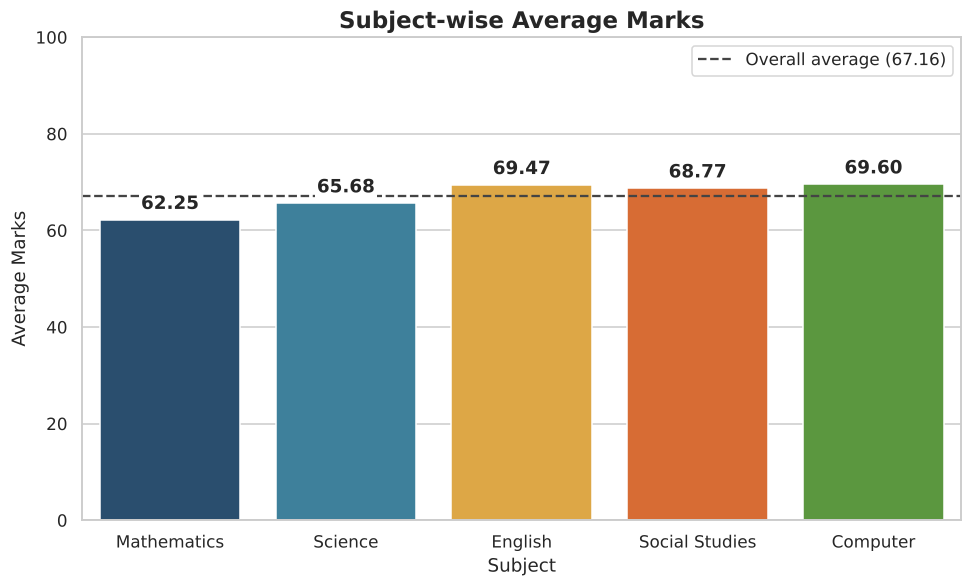

In [ ]:
chart_data = subject_df.copy()
chart_data["Subject"] = chart_data["Subject"].str.replace("_", " ")
overall_average = round(all_marks.mean(), 2)

plt.figure(figsize=(9, 5.5))
ax = sns.barplot(data=chart_data, x="Subject", y="Average_Marks", hue="Subject",
                 palette=SUBJECT_COLORS, legend=False)
# Write the value on top of every bar
for bar in ax.patches:
    if bar.get_height() > 0:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2.2,
                format(bar.get_height(), ".2f"), ha="center", fontweight="bold", zorder=5,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
ax.axhline(overall_average, color="#444444", linestyle="--", linewidth=1.5,
           label="Overall average (" + str(overall_average) + ")")
ax.set_title("Subject-wise Average Marks", fontsize=15, fontweight="bold")
ax.set_xlabel("Subject")
ax.set_ylabel("Average Marks")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
save_chart("01_subject_wise_average_marks.png")

## STEP 16: Chart 2 - Student performance distribution (histogram)

Chart saved: 02_performance_distribution.png


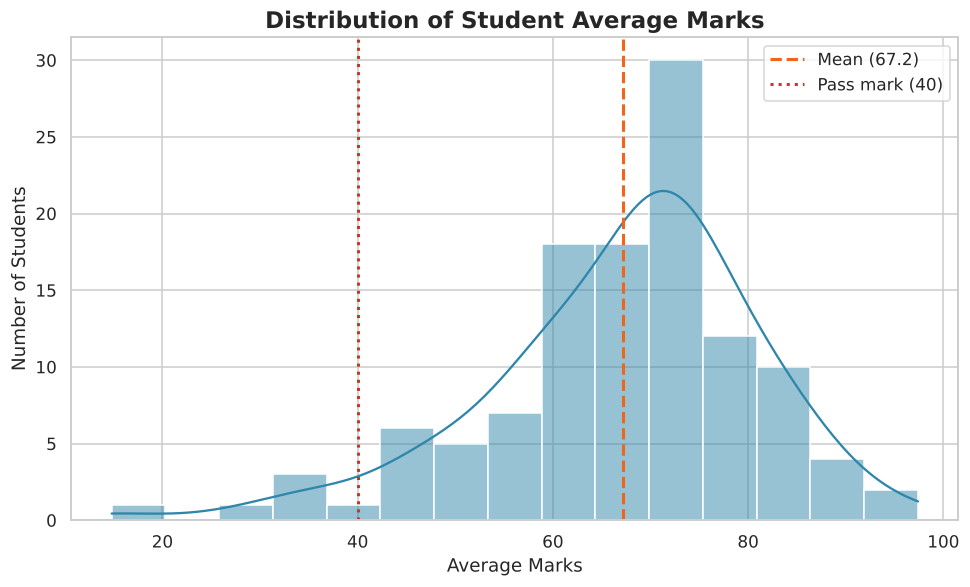

In [ ]:
plt.figure(figsize=(9, 5.5))
ax = sns.histplot(df["Average_Marks"], bins=15, kde=True, color="#2E86AB", edgecolor="white")
ax.axvline(df["Average_Marks"].mean(), color="#F26419", linestyle="--", linewidth=2,
           label="Mean (" + str(round(df["Average_Marks"].mean(), 1)) + ")")
ax.axvline(PASS_MARK, color="#C0392B", linestyle=":", linewidth=2,
           label="Pass mark (" + str(PASS_MARK) + ")")
ax.set_title("Distribution of Student Average Marks", fontsize=15, fontweight="bold")
ax.set_xlabel("Average Marks")
ax.set_ylabel("Number of Students")
ax.legend()
save_chart("02_performance_distribution.png")

## STEP 17: Chart 3 - Pass vs Fail (pie chart)

Chart saved: 03_pass_vs_fail.png


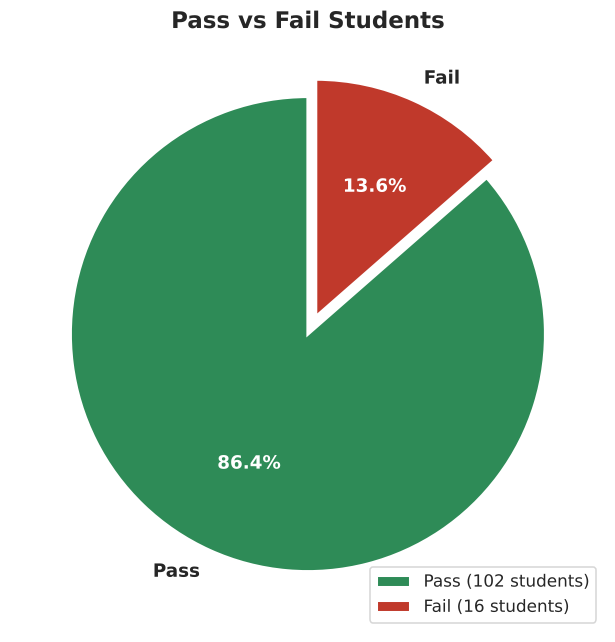

In [ ]:
plt.figure(figsize=(7, 6))
pie_values = [pass_count, fail_count]
pie_labels = ["Pass", "Fail"]
wedges, labels, percent_texts = plt.pie(
    pie_values, labels=pie_labels, autopct="%1.1f%%", startangle=90,
    colors=[RESULT_COLORS["Pass"], RESULT_COLORS["Fail"]], explode=(0, 0.08),
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12, "fontweight": "bold"})
for text in percent_texts:
    text.set_color("white")          # white percentages are easier to read
plt.title("Pass vs Fail Students", fontsize=15, fontweight="bold")
plt.legend(["Pass (" + str(pass_count) + " students)", "Fail (" + str(fail_count) + " students)"],
           loc="lower right")
save_chart("03_pass_vs_fail.png")

## STEP 18: Chart 4 - Gender-wise performance (bar chart)

Chart saved: 04_gender_wise_performance.png


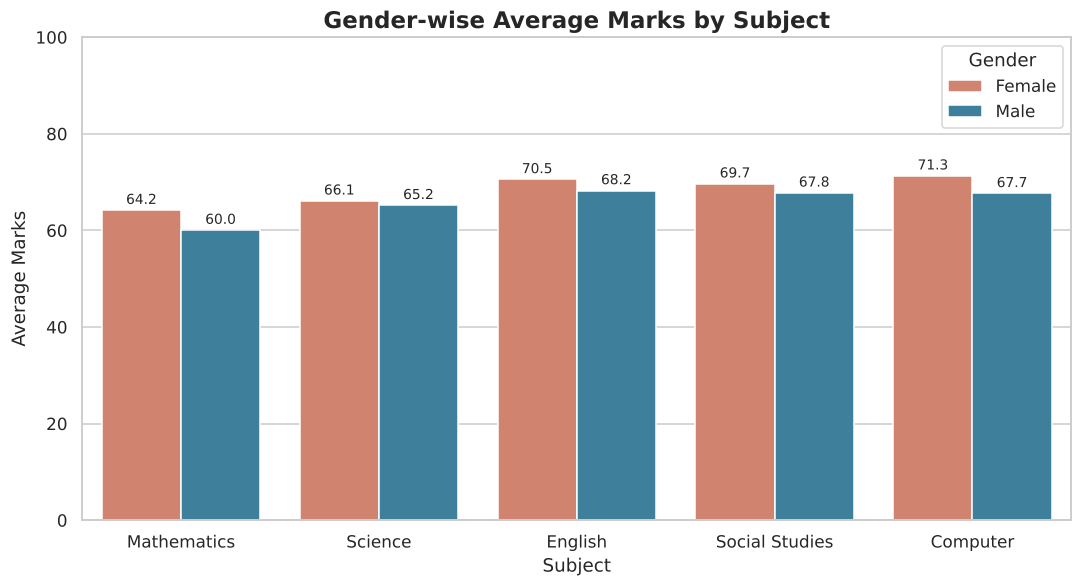

In [ ]:
gender_chart = gender_subject_avg.reset_index().melt(id_vars="Gender", var_name="Subject",
                                                     value_name="Average_Marks")
gender_chart["Subject"] = gender_chart["Subject"].str.replace("_", " ")

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(data=gender_chart, x="Subject", y="Average_Marks", hue="Gender",
                 palette=GENDER_COLORS)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=9)
ax.set_title("Gender-wise Average Marks by Subject", fontsize=15, fontweight="bold")
ax.set_xlabel("Subject")
ax.set_ylabel("Average Marks")
ax.set_ylim(0, 100)
ax.legend(title="Gender", loc="upper right")
save_chart("04_gender_wise_performance.png")

## STEP 19: Chart 5 - Top 10 students (bar chart)

Chart saved: 05_top_10_students.png


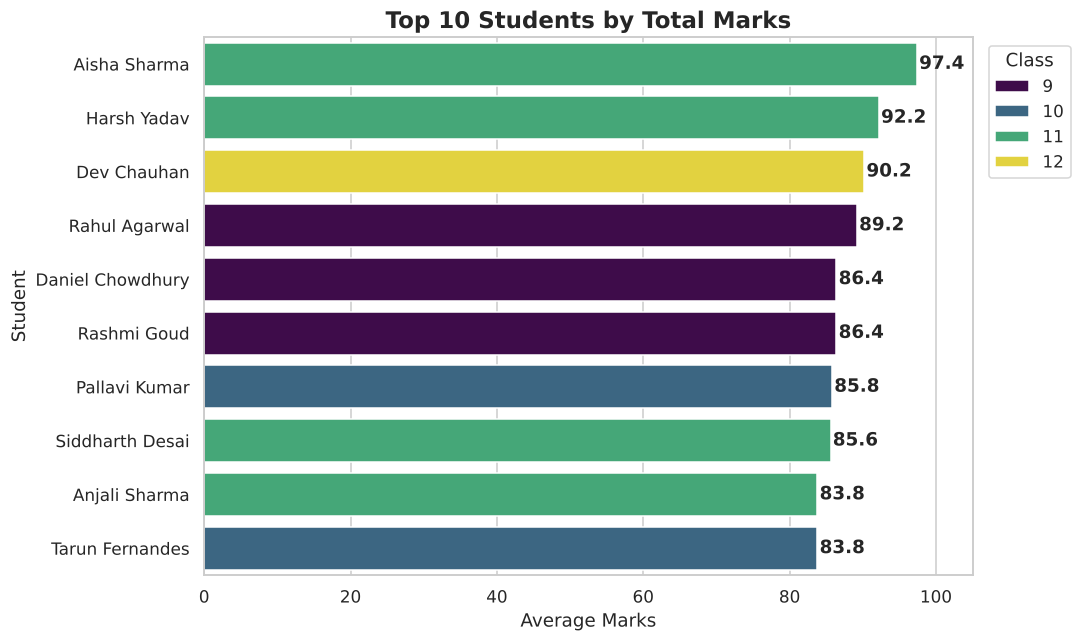

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=top_students, y="Student_Name", x="Average_Marks", hue="Class",
                 dodge=False, palette="viridis")
for bar in ax.patches:
    if bar.get_width() > 0:
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                str(round(bar.get_width(), 1)), va="center", fontweight="bold")
ax.set_title("Top 10 Students by Total Marks", fontsize=15, fontweight="bold")
ax.set_xlabel("Average Marks")
ax.set_ylabel("Student")
ax.set_xlim(0, 105)
ax.legend(title="Class", loc="upper left", bbox_to_anchor=(1.01, 1))
save_chart("05_top_10_students.png")

## STEP 20: Chart 6 - Subject-wise comparison (box plot)

Chart saved: 06_subject_wise_boxplot.png


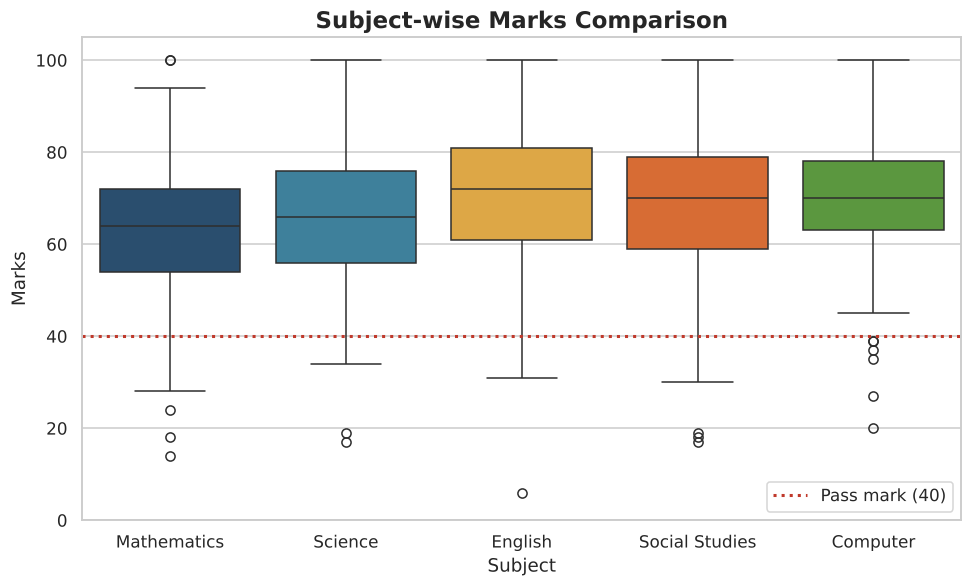

In [ ]:
box_data = df.melt(value_vars=SUBJECTS, var_name="Subject", value_name="Marks")
box_data["Subject"] = box_data["Subject"].str.replace("_", " ")

plt.figure(figsize=(9, 5.5))
ax = sns.boxplot(data=box_data, x="Subject", y="Marks", hue="Subject",
                 palette=SUBJECT_COLORS, legend=False)
ax.axhline(PASS_MARK, color="#C0392B", linestyle=":", linewidth=2,
           label="Pass mark (" + str(PASS_MARK) + ")")
ax.set_title("Subject-wise Marks Comparison", fontsize=15, fontweight="bold")
ax.set_xlabel("Subject")
ax.set_ylabel("Marks")
ax.set_ylim(0, 105)
ax.legend(loc="lower right")
save_chart("06_subject_wise_boxplot.png")

## STEP 21: Create the Excel report

In [ ]:
# Colours and styles used to format the workbook
FONT_NAME = "Arial"
HEADER_FILL = PatternFill("solid", start_color="1F4E79")
HEADER_FONT = Font(name=FONT_NAME, bold=True, color="FFFFFF", size=11)
BODY_FONT = Font(name=FONT_NAME, size=10)
TITLE_FONT = Font(name=FONT_NAME, bold=True, size=13, color="1F4E79")
PASS_FILL = PatternFill("solid", start_color="D9EAD3")
FAIL_FILL = PatternFill("solid", start_color="F4CCCC")
thin_line = Side(style="thin", color="BFBFBF")
CELL_BORDER = Border(left=thin_line, right=thin_line, top=thin_line, bottom=thin_line)


def format_table(sheet, header_row, table, number_formats=None):
    """Format one table: blue header, borders, font and number formats."""
    number_formats = number_formats or {}
    for col_number, column_name in enumerate(table.columns, start=1):
        header_cell = sheet.cell(row=header_row, column=col_number)
        header_cell.font = HEADER_FONT
        header_cell.fill = HEADER_FILL
        header_cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        header_cell.border = CELL_BORDER
        for row_number in range(header_row + 1, header_row + len(table) + 1):
            cell = sheet.cell(row=row_number, column=col_number)
            cell.font = BODY_FONT
            cell.border = CELL_BORDER
            if column_name in number_formats:
                cell.number_format = number_formats[column_name]
                cell.alignment = Alignment(horizontal="center")


def fit_column_widths(sheet, skip_rows=()):
    """Set every column width to fit its longest value."""
    for column_cells in sheet.columns:
        longest = 0
        for cell in column_cells:
            if cell.row in skip_rows or cell.value is None:
                continue
            longest = max(longest, len(str(cell.value)))
        letter = get_column_letter(column_cells[0].column)
        sheet.column_dimensions[letter].width = min(max(longest + 3, 10), 42)


def color_result_cells(sheet, table, header_row):
    """Green background for Pass and red background for Fail."""
    result_col = list(table.columns).index("Result") + 1
    for row_number in range(header_row + 1, header_row + len(table) + 1):
        cell = sheet.cell(row=row_number, column=result_col)
        cell.fill = PASS_FILL if cell.value == "Pass" else FAIL_FILL
        cell.alignment = Alignment(horizontal="center")


# Prepare the tables for each sheet
mark_format = "0"
decimal_format = "0.00"

student_summary = df.sort_values(["Rank", "Student_Name"])[
    ["Rank", "Student_ID", "Student_Name", "Gender", "Class", "Total_Marks", "Average_Marks",
     "Highest_Mark", "Highest_Subject", "Lowest_Mark", "Lowest_Subject", "Result", "Grade"]]

overall_pass_fail = pd.DataFrame({
    "Result": ["Pass", "Fail", "Total"],
    "Students": [pass_count, fail_count, total_students],
    "Percentage": [pass_percentage, round(fail_count / total_students * 100, 2), 100.00],
})

try:
    with pd.ExcelWriter(EXCEL_FILE, engine="openpyxl") as writer:

        # ---- Sheet 1: Cleaned_Data ----
        clean_df.to_excel(writer, sheet_name="Cleaned_Data", index=False)
        sheet = writer.sheets["Cleaned_Data"]
        formats = {name: mark_format for name in SUBJECTS + ["Age", "Class"]}
        format_table(sheet, 1, clean_df, formats)
        fit_column_widths(sheet)
        sheet.freeze_panes = "A2"
        sheet.auto_filter.ref = sheet.dimensions

        # ---- Sheet 2: Student_Summary ----
        student_summary.to_excel(writer, sheet_name="Student_Summary", index=False)
        sheet = writer.sheets["Student_Summary"]
        formats = {"Rank": mark_format, "Class": mark_format, "Total_Marks": mark_format,
                   "Average_Marks": decimal_format, "Highest_Mark": mark_format,
                   "Lowest_Mark": mark_format}
        format_table(sheet, 1, student_summary, formats)
        color_result_cells(sheet, student_summary, 1)
        fit_column_widths(sheet)
        sheet.freeze_panes = "A2"
        sheet.auto_filter.ref = sheet.dimensions

        # ---- Sheet 3: Subject_Analysis ----
        subject_df.to_excel(writer, sheet_name="Subject_Analysis", index=False)
        sheet = writer.sheets["Subject_Analysis"]
        formats = {"Average_Marks": decimal_format, "Highest_Marks": mark_format,
                   "Lowest_Marks": mark_format, "Median_Marks": "0.0",
                   "Std_Deviation": decimal_format, "Passed_Students": mark_format,
                   "Failed_Students": mark_format, "Pass_Percentage": decimal_format,
                   "Rank_By_Average": mark_format}
        format_table(sheet, 1, subject_df, formats)
        fit_column_widths(sheet)
        sheet.freeze_panes = "A2"

        # ---- Sheet 4: Pass_Fail_Analysis (several small tables, one below the other) ----
        sheet_name = "Pass_Fail_Analysis"
        row = 1                       # Excel row where the next table title is written
        title_rows = []

        tables_to_write = [
            ("Overall Pass / Fail Summary", overall_pass_fail,
             {"Students": mark_format, "Percentage": decimal_format}),
            ("Pass / Fail by Gender", pass_fail_gender,
             {"Total_Students": mark_format, "Passed": mark_format,
              "Failed": mark_format, "Pass_Percentage": decimal_format}),
            ("Pass / Fail by Class", pass_fail_class,
             {"Class": mark_format, "Total_Students": mark_format, "Passed": mark_format,
              "Failed": mark_format, "Pass_Percentage": decimal_format}),
            ("Students Who Failed (pass mark = " + str(PASS_MARK) + " in every subject)",
             failed_students, {"Average_Marks": decimal_format}),
        ]

        for title, table, formats in tables_to_write:
            if len(table) == 0:
                table = pd.DataFrame({"Message": ["No students failed"]})
            table.to_excel(writer, sheet_name=sheet_name, index=False, startrow=row)
            sheet = writer.sheets[sheet_name]
            sheet.cell(row=row, column=1, value=title).font = TITLE_FONT
            title_rows.append(row)
            format_table(sheet, row + 1, table, formats)
            row = row + len(table) + 3          # title + header + rows + blank line

        sheet = writer.sheets[sheet_name]
        fit_column_widths(sheet, skip_rows=title_rows)

        # ---- Sheet 5: Top_Students ----
        top_students.to_excel(writer, sheet_name="Top_Students", index=False)
        sheet = writer.sheets["Top_Students"]
        formats = {name: mark_format for name in SUBJECTS + ["Rank", "Class", "Total_Marks"]}
        formats["Average_Marks"] = decimal_format
        format_table(sheet, 1, top_students, formats)
        fit_column_widths(sheet)
        sheet.freeze_panes = "A2"

    print("Excel report saved to:", short_path(EXCEL_FILE))

except PermissionError:
    print("Could not save the Excel report. Close", EXCEL_FILE.name,
          "if it is open in Excel, then run the script again.")

Excel report saved to: outputs/student_performance_report.xlsx


## STEP 22: Final student performance summary

In [ ]:
top_student = top_students.iloc[0]

print("=" * 55)
print("        STUDENT PERFORMANCE - FINAL SUMMARY")
print("=" * 55)
print("Total students            :", total_students)
print("Overall average marks     :", overall_average)
print("Highest single mark       :", int(all_marks.max()))
print("Lowest single mark        :", int(all_marks.min()))
print("Passed / Failed           :", pass_count, "/", fail_count)
print("Overall pass percentage   :", pass_percentage, "%")
print("Highest-performing subject:", best_subject,
      "(average", subject_df.loc[subject_df["Subject"] == best_subject, "Average_Marks"].iloc[0], ")")
print("Lowest-performing subject :", worst_subject,
      "(average", subject_df.loc[subject_df["Subject"] == worst_subject, "Average_Marks"].iloc[0], ")")
print("Top student               :", top_student["Student_Name"],
      "(average", top_student["Average_Marks"], ")")
print("Grade distribution        :", df["Grade"].value_counts().sort_index().to_dict())
print("=" * 55)
print("Charts folder :", short_path(CHARTS_DIR))
print("Excel report  :", short_path(EXCEL_FILE))
print("Project completed successfully.")

        STUDENT PERFORMANCE - FINAL SUMMARY
Total students            : 118
Overall average marks     : 67.16
Highest single mark       : 100
Lowest single mark        : 6
Passed / Failed           : 102 / 16
Overall pass percentage   : 86.44 %
Highest-performing subject: Computer (average 69.6 )
Lowest-performing subject : Mathematics (average 62.25 )
Top student               : Aisha Sharma (average 97.4 )
Grade distribution        : {'A': 16, 'A+': 3, 'B': 39, 'C': 29, 'D': 14, 'E': 1, 'F': 16}
Charts folder : outputs/charts
Excel report  : outputs/student_performance_report.xlsx
Project completed successfully.


## Key Findings

- **118** valid students after cleaning (5 raw rows removed: 3 duplicates and 2 invalid records).
- Overall pass percentage is **86.44 %** (102 passed, 16 failed). Overall average mark is **67.16**.
- **Computer** is the highest-performing subject (average 69.60) and **Mathematics** is the lowest (average 62.25).
- Mathematics also has the most failures (12 students). Four of the six students who failed in only one subject failed in Mathematics.
- Female students have a slightly higher average (68.36 vs 65.78) and pass percentage (88.89 % vs 83.64 %) than male students in this sample.
- Class 9 has the best pass percentage (90.62 %); Class 12 has the lowest average (64.19) and the lowest pass percentage (82.14 %).
- **Aisha Sharma** (Class 11) is the top student with an average of 97.4. Only 3 students reached grade A+.
- Five students failed in four or five subjects - they need urgent academic support.

## Output Files

- `data/cleaned_student_performance.csv`
- `outputs/charts/` - 6 PNG charts
- `outputs/student_performance_report.xlsx` - 5 formatted sheets
